# Dự đoán nguy cơ đái tháo đường — Pima Indians Diabetes

Nghiên cứu thực nghiệm trên dữ liệu có sẵn, không dùng để chẩn đoán. Tập dữ liệu Pima không đại diện cho mọi quần thể. Chia tập test trước khi học mọi tham số tiền xử lý; chọn mô hình bằng F1 trung bình của cross-validation trên train, sau đó chỉ đánh giá test cho mô hình đã chọn. Ngưỡng phân loại mặc định 0,5 không được xác nhận lâm sàng.

In [1]:
from pathlib import Path
import sys, json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, shap, sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay, confusion_matrix

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'diabetes.csv').exists())
MODEL_DIR = ROOT / 'output' / 'model'
MODEL_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
print('Python:', sys.version.split()[0], '| sklearn:', sklearn.__version__, '| SHAP:', shap.__version__)
df = pd.read_csv(ROOT / 'data' / 'diabetes.csv')
display(df.head())
print('Kích thước:', df.shape, '| Trùng toàn bộ:', df.duplicated().sum())

C:\Users\kduy7\miniconda3\envs\start_ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.11.15 | sklearn: 1.9.0 | SHAP: 0.51.0


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Kích thước: (768, 9) | Trùng toàn bộ: 0


## Khảo sát dữ liệu

Các giá trị 0 trong Glucose, BloodPressure, SkinThickness, Insulin và BMI được xem là thiếu theo quy ước thường dùng cho bộ Pima; không áp dụng cho Pregnancies. Thống kê chỉ mô tả dữ liệu, không dùng test để điều chỉnh mô hình.

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


Nhãn: {0: 500, 1: 268}
Thiếu tường minh: {'Pregnancies': 0, 'Glucose': 0, 'BloodPressure': 0, 'SkinThickness': 0, 'Insulin': 0, 'BMI': 0, 'DiabetesPedigreeFunction': 0, 'Age': 0, 'Outcome': 0}
Số giá trị 0 xem là thiếu: {'Glucose': 5, 'BloodPressure': 35, 'SkinThickness': 227, 'Insulin': 374, 'BMI': 11}


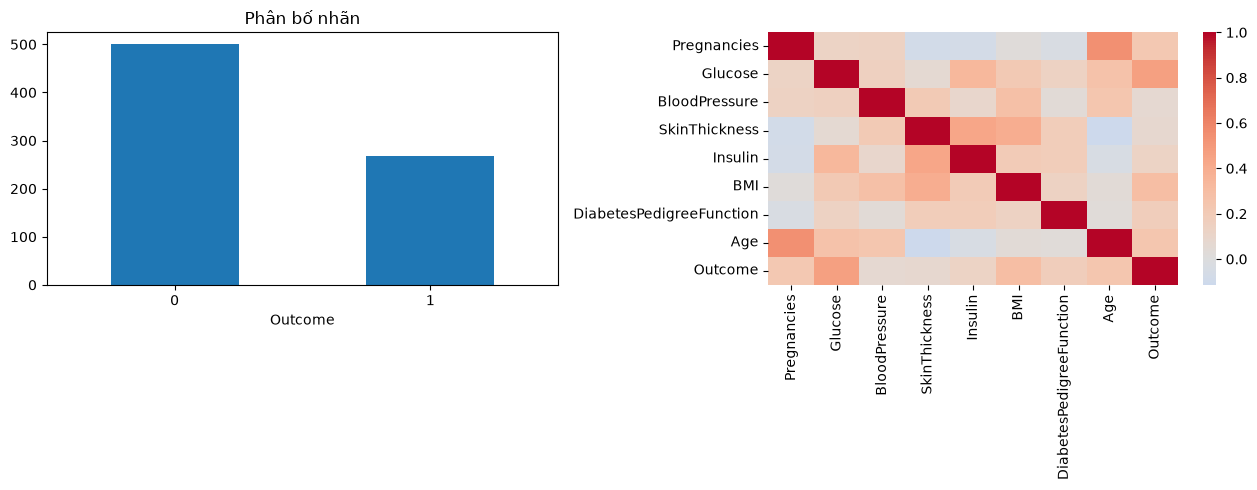

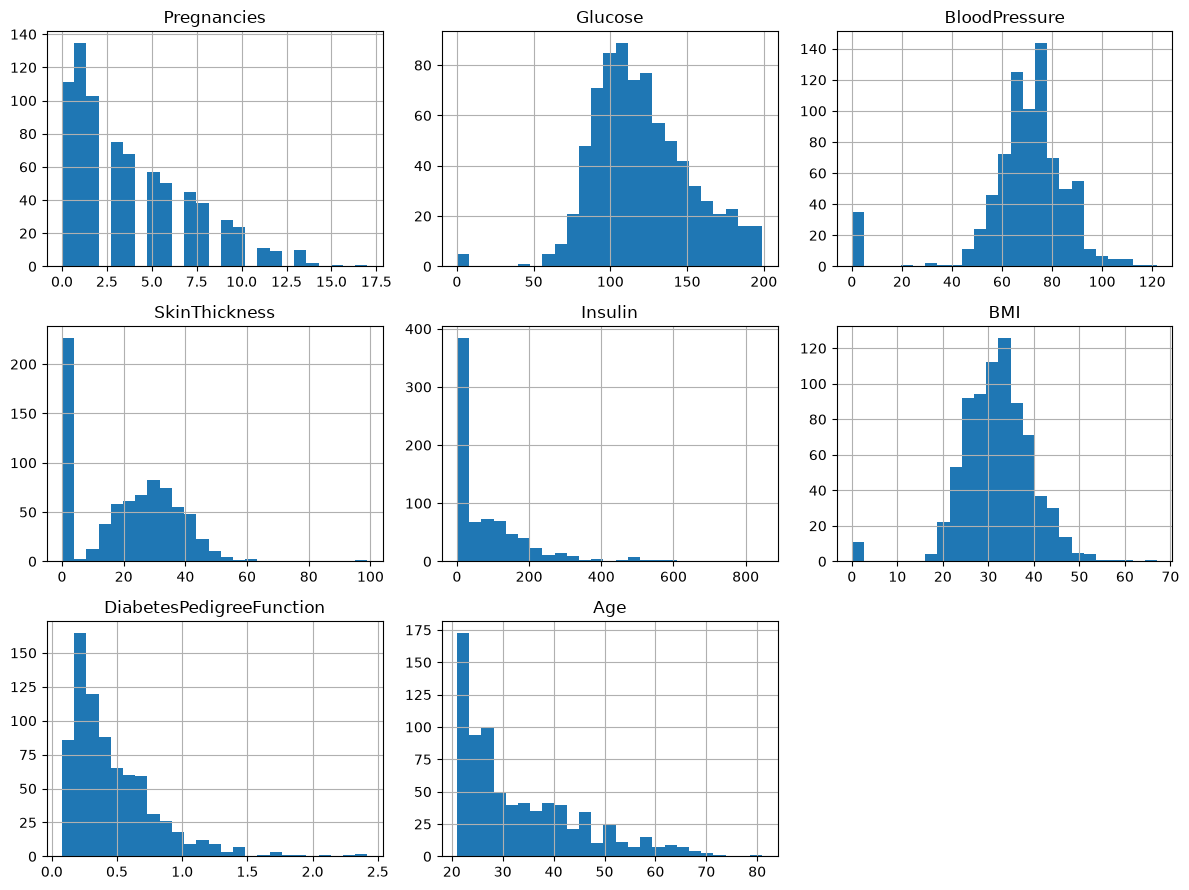

In [2]:
display(df.describe().T)
print('Nhãn:', df['Outcome'].value_counts().to_dict())
print('Thiếu tường minh:', df.isna().sum().to_dict())
ZERO_COLUMNS = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
print('Số giá trị 0 xem là thiếu:', (df[ZERO_COLUMNS] == 0).sum().to_dict())
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
df['Outcome'].value_counts().sort_index().plot.bar(ax=axes[0], title='Phân bố nhãn', rot=0)
sns.heatmap(df.corr(), cmap='coolwarm', center=0, ax=axes[1])
plt.tight_layout(); plt.show()
df.drop(columns='Outcome').hist(figsize=(12, 9), bins=25); plt.tight_layout(); plt.show()

## Chia dữ liệu và huấn luyện

Chia phân tầng 80/20 với seed 42. Median imputation và standardization được fit riêng trong từng fold nhờ Pipeline. So sánh 5 mô hình mặc định bằng 5-fold stratified CV; xếp theo F1, hòa thì ROC-AUC. Không chọn theo kết quả test.

In [3]:
FEATURES = [c for c in df.columns if c != 'Outcome']
assert set(df['Outcome'].unique()) == {0, 1}
X, y = df[FEATURES], df['Outcome']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print('Train:', len(X_train), '| Test:', len(X_test))

def make_pipeline(estimator):
    preprocessing = ColumnTransformer([
        ('zero_missing', SimpleImputer(missing_values=0, strategy='median'), ZERO_COLUMNS),
        ('other', SimpleImputer(strategy='median'), [c for c in FEATURES if c not in ZERO_COLUMNS]),
    ], verbose_feature_names_out=False)
    return Pipeline([('preprocess', preprocessing), ('scale', StandardScaler()), ('model', estimator)])

models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=SEED),
    'KNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1),
    'SVM': SVC(probability=True, random_state=SEED),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {'accuracy':'accuracy', 'precision':'precision', 'recall':'recall', 'f1':'f1', 'roc_auc':'roc_auc'}
rows = []
for name, estimator in models.items():
    result = cross_validate(make_pipeline(estimator), X_train, y_train, cv=cv, scoring=scoring, error_score='raise')
    rows.append({'model': name, **{metric: result['test_' + metric].mean() for metric in scoring}, 'f1_std': result['test_f1'].std()})
comparison = pd.DataFrame(rows).sort_values(['f1', 'roc_auc'], ascending=False).reset_index(drop=True)
display(comparison.round(4))
selected = comparison.loc[0, 'model']
print('Mô hình được chọn theo CV:', selected)
pipeline = make_pipeline(models[selected]).fit(X_train, y_train)

Train: 614 | Test: 154


C:\Users\kduy7\miniconda3\envs\start_ml\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\kduy7\miniconda3\envs\start_ml\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\kduy7\miniconda3\envs\start_ml\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\kduy7\miniconda3\envs\start_ml\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\kduy7\miniconda3\envs\start_ml\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,model,accuracy,precision,recall,f1,roc_auc,f1_std
0,Logistic Regression,0.7882,0.7638,0.5748,0.6545,0.8434,0.0244
1,SVM,0.7801,0.7415,0.5842,0.6485,0.8333,0.0187
2,Random Forest,0.7622,0.6930,0.5843,0.6308,0.8155,0.0272
3,KNN,0.7296,0.6367,0.5654,0.5939,0.7843,0.0469
4,Decision Tree,0.6808,0.5417,0.5514,0.5457,0.6507,0.0257


Mô hình được chọn theo CV: Logistic Regression


## Đánh giá trên test giữ riêng

Các chỉ số sau chỉ là ước lượng trên một lần chia, không phải hiệu năng lâm sàng. Ma trận theo thứ tự thực tế [0, 1], dự đoán [0, 1].

,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.7078,0.6,0.5,0.5455,0.813


Confusion matrix: [[82, 18], [27, 27]]


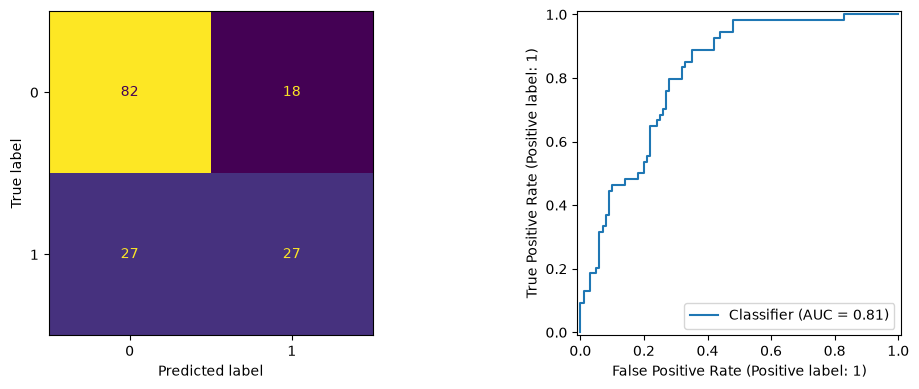

In [4]:
pred = pipeline.predict(X_test)
prob = pipeline.predict_proba(X_test)[:, 1]
metrics = {'accuracy': accuracy_score(y_test, pred), 'precision': precision_score(y_test, pred, zero_division=0), 'recall': recall_score(y_test, pred, zero_division=0), 'f1': f1_score(y_test, pred, zero_division=0), 'roc_auc': roc_auc_score(y_test, prob)}
display(pd.DataFrame([metrics], index=[selected]).round(4))
matrix = confusion_matrix(y_test, pred, labels=[0,1])
print('Confusion matrix:', matrix.tolist())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(matrix, display_labels=[0,1]).plot(ax=axes[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, prob, ax=axes[1]); plt.tight_layout(); plt.show()

## SHAP

Kernel SHAP giải thích xác suất lớp 1 của toàn bộ pipeline, dùng mẫu nền lấy từ train; 20 mẫu test đầu chỉ để minh họa. Đây là mức đóng góp của mô hình so với mẫu nền, không chứng minh quan hệ nhân quả.

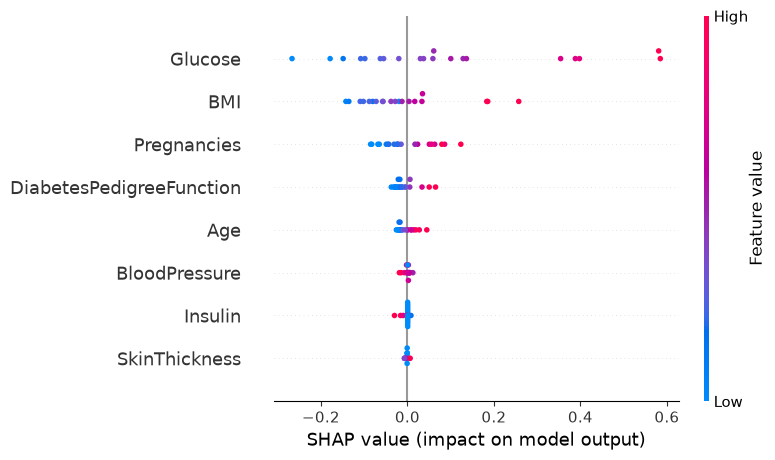

,feature,mean_abs_shap
1,Glucose,0.189827
5,BMI,0.082852
0,Pregnancies,0.052560
6,DiabetesPedigreeFunction,0.023495
7,Age,0.016547
2,BloodPressure,0.004607
4,Insulin,0.004055
3,SkinThickness,0.002768


In [5]:
background = shap.sample(X_train, min(50, len(X_train)), random_state=SEED)
explain_data = X_test.iloc[:20].copy()
def probability_for_shap(values):
    return pipeline.predict_proba(pd.DataFrame(values, columns=FEATURES))[:, 1]
explainer = shap.KernelExplainer(probability_for_shap, background)
shap_values = explainer.shap_values(explain_data, nsamples=256, silent=True)
shap.summary_plot(shap_values, explain_data, show=False)
plt.tight_layout(); plt.show()
display(pd.DataFrame({'feature': FEATURES, 'mean_abs_shap': np.abs(shap_values).mean(axis=0)}).sort_values('mean_abs_shap', ascending=False))

## Lưu và dự đoán

`diabetes_pipeline.joblib` bao gồm tiền xử lý và mô hình; `diabetes_model.joblib` chỉ chứa estimator và không thể dự đoán đúng từ dữ liệu thô nếu thiếu tiền xử lý. Chỉ nạp các file joblib tin cậy. Hàm `predict` nhận dict hoặc danh sách dict, kiểm tra đúng 8 trường, rồi dùng pipeline lưu sẵn. Khi tích hợp, dùng cùng phiên bản scikit-learn và chuyển hàm này vào module tích hợp thích hợp.

In [6]:
joblib.dump(pipeline, MODEL_DIR / 'diabetes_pipeline.joblib')
joblib.dump(pipeline.named_steps['model'], MODEL_DIR / 'diabetes_model.joblib')

def predict(records, pipeline_path=MODEL_DIR / 'diabetes_pipeline.joblib'):
    """Dự đoán từ dict hoặc list[dict]; trả nhãn và xác suất lớp 1."""
    if isinstance(records, dict):
        records = [records]
    if not isinstance(records, list) or not records or any(not isinstance(r, dict) for r in records):
        raise ValueError('Đầu vào phải là dict hoặc danh sách dict không rỗng.')
    if any(set(r) != set(FEATURES) for r in records):
        raise ValueError(f'Cần đúng các trường: {FEATURES}')
    frame = pd.DataFrame(records, columns=FEATURES).apply(pd.to_numeric, errors='raise')
    if not np.isfinite(frame.to_numpy(dtype=float)).all() or (frame < 0).any().any():
        raise ValueError('Các giá trị phải là số hữu hạn và không âm.')
    loaded = joblib.load(pipeline_path)
    labels = loaded.predict(frame)
    probabilities = loaded.predict_proba(frame)[:, 1]
    return [{'prediction': int(label), 'probability': float(probability)} for label, probability in zip(labels, probabilities)]

test_records = X_test.iloc[:3].to_dict(orient='records')
results = predict(test_records)
assert np.allclose([r['probability'] for r in results], pipeline.predict_proba(X_test.iloc[:3])[:, 1])
try:
    predict({'Age': 30})
    raise AssertionError('Thiếu trường phải bị từ chối')
except ValueError:
    pass
print('Kiểm tra load/predict và từ chối đầu vào thiếu: đạt')
print('Đã lưu:', MODEL_DIR / 'diabetes_pipeline.joblib', 'và', MODEL_DIR / 'diabetes_model.joblib')
summary = {'selected_model': selected, 'cv': comparison.to_dict(orient='records'), 'test': metrics, 'confusion_matrix': matrix.tolist(), 'train_size': len(X_train), 'test_size': len(X_test), 'versions': {'python': platform.python_version(), 'sklearn': sklearn.__version__, 'shap': shap.__version__}}
print('RESULT_JSON:', json.dumps(summary, ensure_ascii=False))

Kiểm tra load/predict và từ chối đầu vào thiếu: đạt
Đã lưu: D:\AI\DiabetesMultiAgent\output\model\diabetes_pipeline.joblib và D:\AI\DiabetesMultiAgent\output\model\diabetes_model.joblib
RESULT_JSON: {"selected_model": "Logistic Regression", "cv": [{"model": "Logistic Regression", "accuracy": 0.7882313741170198, "precision": 0.7638075920023182, "recall": 0.5747508305647842, "f1": 0.6545454545454545, "roc_auc": 0.8433637873754153, "f1_std": 0.024423199069116826}, {"model": "SVM", "accuracy": 0.7801279488204719, "precision": 0.7415343915343915, "recall": 0.5841638981173864, "f1": 0.648461736901125, "roc_auc": 0.8333084163898116, "f1_std": 0.018709830329590033}, {"model": "Random Forest", "accuracy": 0.7622151139544182, "precision": 0.6929823481116584, "recall": 0.5842746400885935, "f1": 0.6307550900770839, "roc_auc": 0.815500415282392, "f1_std": 0.027214022060129843}, {"model": "KNN", "accuracy": 0.7295881647341064, "precision": 0.6367078697669678, "recall": 0.5654485049833887, "f1": 0.59